In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
from xgboost import XGBRegressor

RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ))
from src.features import BASE, DERIVADAS

df = pd.read_csv(RAIZ / "data" / "processed" / "concreto_features.csv")
TODAS = BASE + DERIVADAS
X, y = df[TODAS], df["resistencia"]

with open(RAIZ / "models" / "mejores_hiperparametros.json") as f:
    params = json.load(f)["XGBoost"]

final = XGBRegressor(**params, random_state=42, n_jobs=1).fit(X, y)
final.save_model(RAIZ / "models" / "xgb_final.json")

# Comprobación: el archivo guardado reproduce las predicciones
recargado = XGBRegressor()
recargado.load_model(RAIZ / "models" / "xgb_final.json")
print("Predicciones idénticas:", np.allclose(final.predict(X), recargado.predict(X)))

Predicciones idénticas: True


c:\Users\danie\Documents\predictor-concreto\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


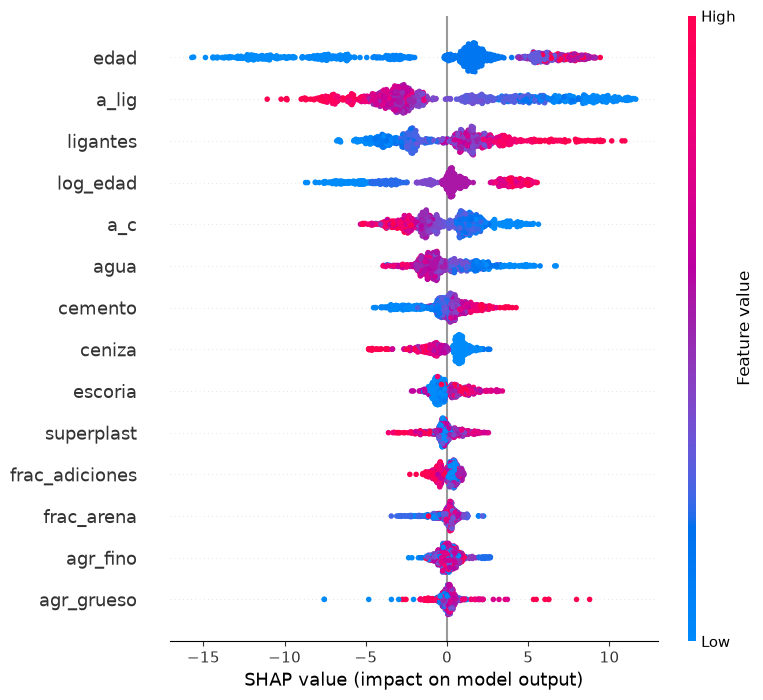

edad              5.04
a_lig             4.58
ligantes          2.72
log_edad          2.61
a_c               1.83
agua              1.32
cemento           1.05
ceniza            0.97
escoria           0.69
superplast        0.58
frac_adiciones    0.47
frac_arena        0.47
agr_fino          0.47
agr_grueso        0.41
dtype: float32

In [2]:
import shap
import matplotlib.pyplot as plt

explicador = shap.TreeExplainer(final)
sv = explicador(X)

FIG = RAIZ / "reports" / "figures"
plt.figure()
shap.plots.beeswarm(sv, max_display=14, show=False)
plt.tight_layout()
plt.savefig(FIG / "08_shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

importancia = pd.Series(np.abs(sv.values).mean(axis=0), index=TODAS)
importancia.sort_values(ascending=False).round(2)

In [3]:
j = TODAS.index("frac_adiciones")
grupo = pd.cut(df["edad"], [0, 7, 28, 400], labels=["≤7 d", "8–28 d", ">28 d"])
nivel = np.where(df["frac_adiciones"] > 0.3, "alta (>0.3)", "baja (≤0.3)")

pd.DataFrame({"SHAP": sv.values[:, j], "grupo": grupo, "adiciones": nivel}) \
  .groupby(["grupo", "adiciones"], observed=True)["SHAP"].mean() \
  .unstack().round(2)

adiciones,alta (>0.3),baja (≤0.3)
grupo,,
≤7 d,-0.44,0.49
8–28 d,-0.27,0.26
>28 d,-0.07,0.21


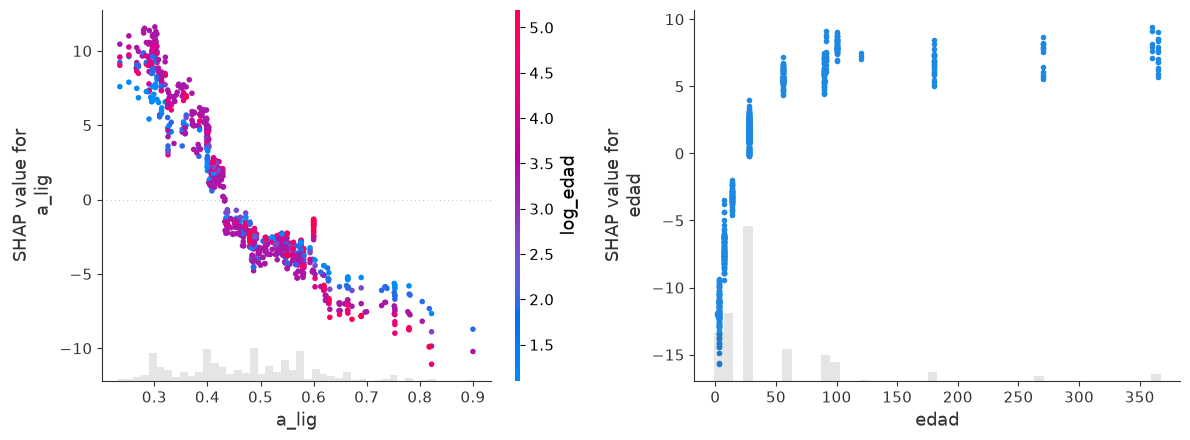

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
shap.plots.scatter(sv[:, "a_lig"], color=sv[:, "log_edad"], ax=axes[0], show=False)
shap.plots.scatter(sv[:, "edad"], ax=axes[1], show=False)
plt.tight_layout()
plt.savefig(FIG / "09_shap_dependencia.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
from src.features import agregar_variables

ref = pd.DataFrame([{"cemento": 350, "escoria": 0, "ceniza": 0, "agua": 180,
                     "superplast": 0, "agr_grueso": 1000, "agr_fino": 800,
                     "edad": 28}])

def barrido(col, valores):
    filas = pd.concat([ref] * len(valores), ignore_index=True)
    filas[col] = valores
    pred = final.predict(agregar_variables(filas)[TODAS])
    return pd.Series(pred, index=valores).round(1)

print("Agua (kg/m³):");    print(barrido("agua", [140, 160, 180, 200, 220]), "\n")
print("Cemento (kg/m³):"); print(barrido("cemento", [250, 300, 350, 400, 450, 500]), "\n")
print("Edad (días):");     print(barrido("edad", [1, 3, 7, 14, 28, 56, 90, 180, 365]))

Agua (kg/m³):
140    46.900002
160    38.500000
180    32.799999
200    29.799999
220    26.000000
dtype: float32 

Cemento (kg/m³):
250    22.900000
300    27.600000
350    32.799999
400    39.700001
450    46.099998
500    55.500000
dtype: float32 

Edad (días):
1      15.200000
3      15.200000
7      19.900000
14     27.200001
28     32.799999
56     38.799999
90     40.900002
180    42.799999
365    43.799999
dtype: float32
